## Анализ и прогнозирование временных рядов методами искусственного интеллекта

### **Практическая работа 3. Поиск аномалий во временных рядах.**


#### **3.1 Поиск диссонансов с помощью алгоритма HotSAX**

##### 3.1.1 Загрузка и подготовка данных

В данной будет использоваться временной ряд, состоящий из показаний акселерометра.
Анализируемый временной ряд, описывает две активности человека - бег и шаг.


In [2]:
!pip install scipy
!pip install scikit-learn

In [3]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from time import time
import pandas as pd

In [4]:
#fixme: Путь
dataset_dir_path = Path('datasets')
data_path = dataset_dir_path/'walk_run.txt'
walk_run = np.loadtxt(data_path)[3000:4000]
data = walk_run
size_sub = 50

В середине временного ряда происходит смена активности (бег заменяет шаг). Нетипичным поведением, которое мы могли бы назвать диссонансами в данном ряде выступает небольшой участок между активностями, когда человек плавно увеличивает скорость шага до бега. В ходе данной работе наша задача выделить с помощью различных алгоритмов границы нашего диссонанса.

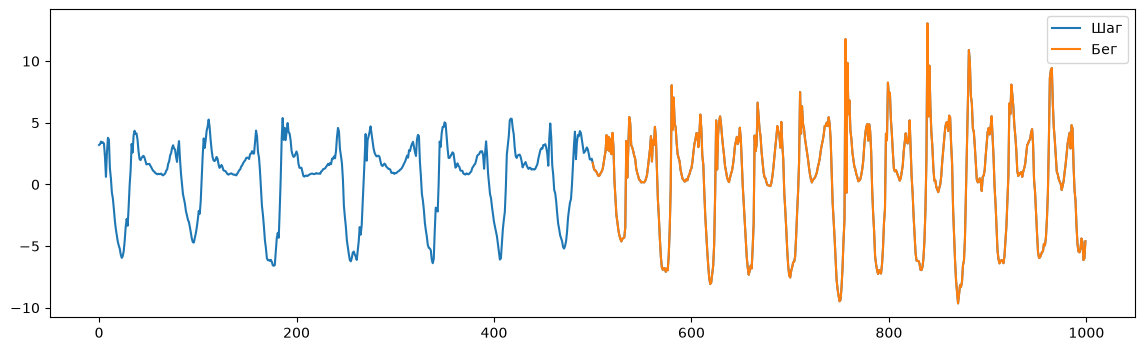

In [5]:
fig, ax =  plt.subplots(figsize=(14,4),ncols=1,nrows=1)
plt.plot(data[:],label='Шаг')
plt.plot(np.arange(data.shape[0]//2,data.shape[0]),data[data.shape[0]//2:],label='Бег')
plt.legend()

In [6]:
result={}
times={}

##### 3.1.2 Реализация полного перебора

Приводится пример кода для нахождения топ 5 диссонансов с помощью реализации полного беребора.
Вам необходимо добавить код для сбора времени обработки данных.

In [7]:
from modules.saxpy.discord import find_discords_brute_force

start = time()
discords_brute_force = np.stack(find_discords_brute_force(data[:], 50, 5))
end = time()

times['brute_force'] = end - start
result['brute_force'] = discords_brute_force

print(f"Brute force time: {times['brute_force']:.4f} sec")
print(f"Найдено диссонансов: {len(discords_brute_force)}")

Brute force time: 50.0921 sec
Найдено диссонансов: 5


##### 3.1.3 HotSAX

Используя [реализацию](https://github.com/seninp/saxpy/blob/master/saxpy/hotsax.py) найдите топ 5 диссонансов ряда.
Произведите замер времени работы.

In [8]:
from modules.saxpy.hotsax import find_discords_hotsax

start = time()
discords_hotsax = np.stack(find_discords_hotsax(data[:], win_size=50, num_discords=5))
end = time()

times['hotsax'] = end - start
result['hotsax'] = discords_hotsax

print(f"HotSAX time: {times['hotsax']:.4f} sec")
# INSERT YOUR CODE

HotSAX time: 0.9597 sec


##### 3.1.4 Визаулизация

Вам необходимо реализовать код позволяющий:
1. Вывести на одном графике ряд и его диссонансы
2. Столбчатую диаграмму времени работы обоих алгоритмов

Постройте графики для обоих алгоритмов и сравните полученные результаты.

Пример графика:

![first_graf](pics/fig_ex_1.png)

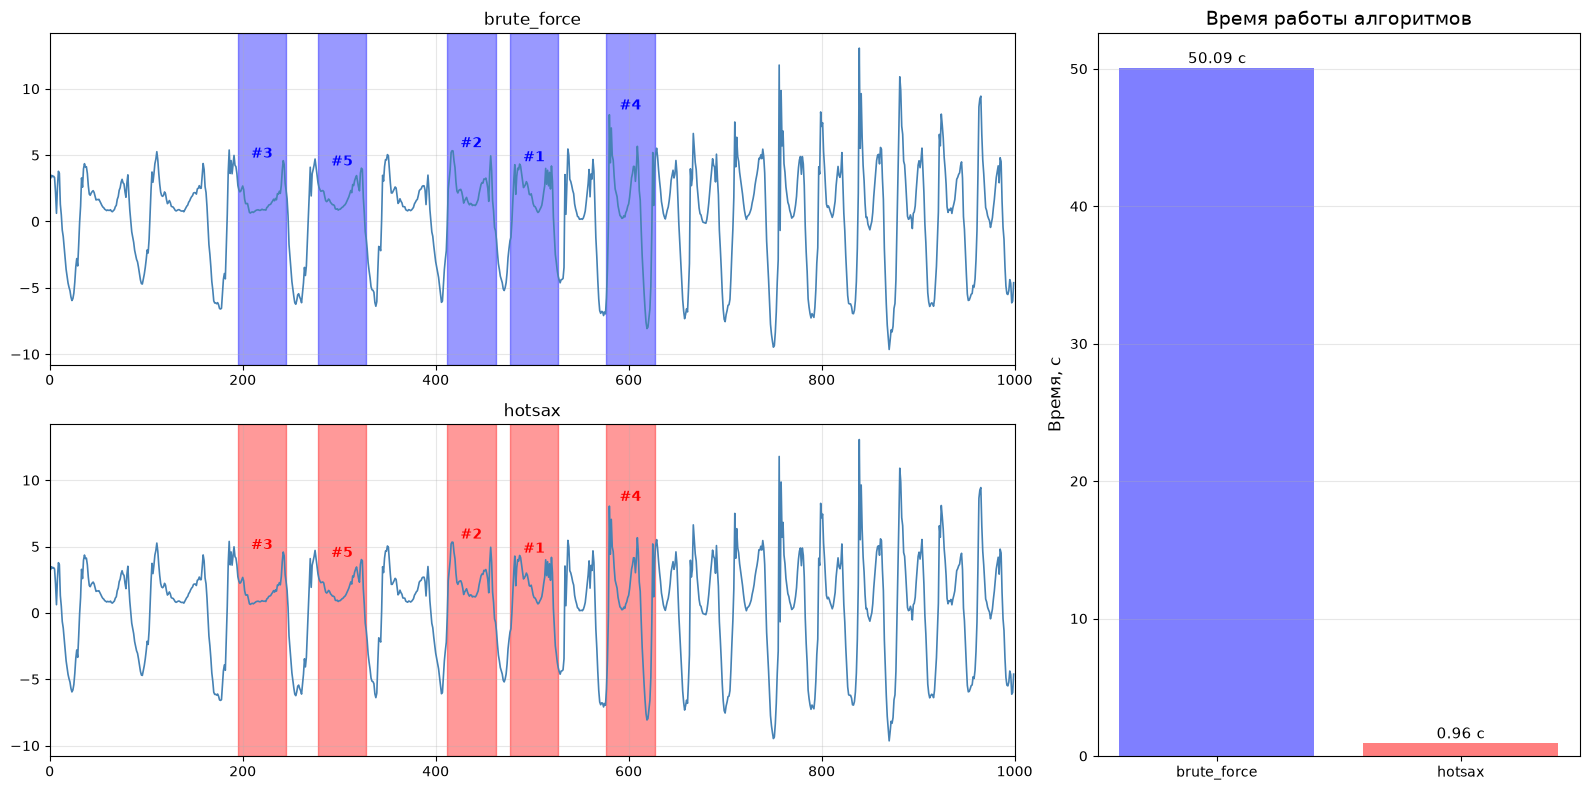

In [9]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np

def plot_series_with_discords(ax, series, discords, m, color, title):
    ax.plot(series, color='steelblue', lw=1.2, label='Ряд')

    for i, d in enumerate(discords):
        idx = int(d[0])

        ax.axvspan(idx, idx + m, color=color, alpha=0.4)

        y_pos = np.max(series[idx:idx+m]) * 1.05
        ax.text(idx + m/2, y_pos, f'#{i+1}', color=color,
                fontsize=10, fontweight='bold', ha='center')

    ax.set_title(title, fontsize=12)
    ax.set_xlim(0, len(series))
    ax.grid(True, alpha=0.3)

fig = plt.figure(figsize=(16, 8))
gs = fig.add_gridspec(2, 2, width_ratios=[2, 1])

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[:, 1])

plot_series_with_discords(ax1, data, result['brute_force'], m=50,
                          color='blue', title='brute_force')

plot_series_with_discords(ax2, data, result['hotsax'], m=50,
                          color='red', title='hotsax')


algorithms = list(times.keys())
execution_times = list(times.values())

bars = ax3.bar(algorithms, execution_times, color=['blue', 'red'], alpha=0.5)
ax3.set_ylabel('Время, с', fontsize=12)
ax3.set_title('Время работы алгоритмов', fontsize=14)
ax3.grid(axis='y', alpha=0.3)

for bar in bars:
    yval = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2, yval + 0.05,
             f'{yval:.2f} с', ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()

In [10]:
from matplotlib.patches import Rectangle

##### 3.1.5 Такси NY

Произведите поиск диссонансов с помощью обоих алгоритмов на наборе данных, содержащим информацию о среднем числе пассажиров в NY. Отобразите найденные диссонансы обоими алгоритмами.

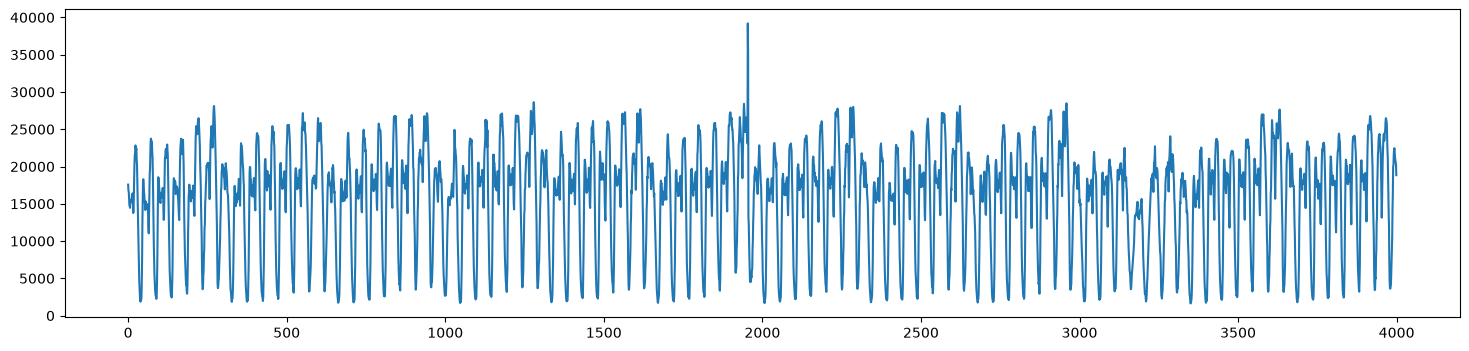

In [11]:
nyc_taxi = pd.read_csv(dataset_dir_path/'nyc_taxi.csv',index_col=0).values[4000:8000,0].astype(np.float64)
fig = plt.figure(figsize=(18, 4))
plt.plot(nyc_taxi)

# INSERT YOUR CODE

NYC Brute force time: 1252.1121 sec
NYC HotSAX time: 3.6483 sec


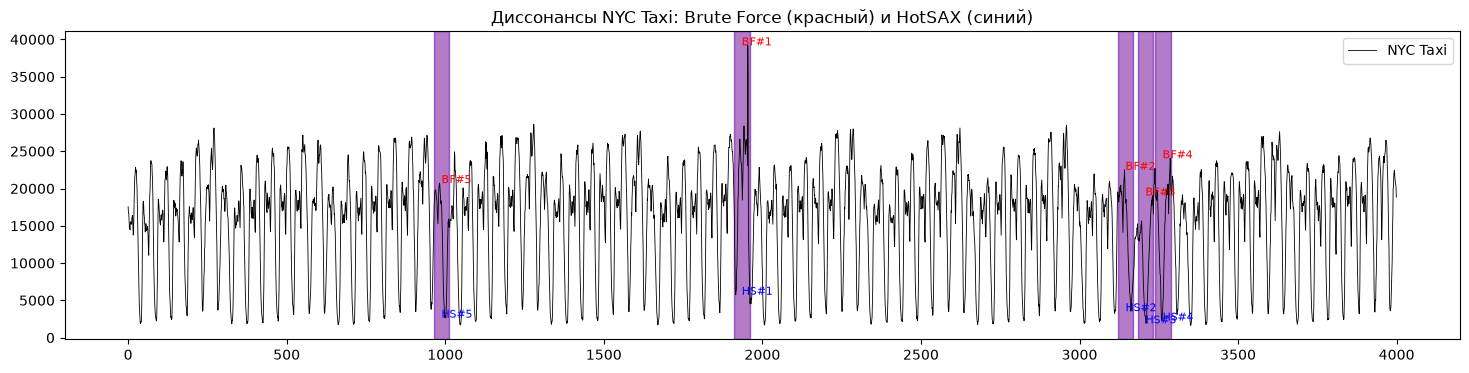

In [12]:
nyc_taxi = pd.read_csv(dataset_dir_path/'nyc_taxi.csv',index_col=0).values[4000:8000,0].astype(np.float64)

start = time()
discords_taxi_bf = np.stack(find_discords_brute_force(nyc_taxi, 50, 5))
end = time()
print(f"NYC Brute force time: {end - start:.4f} sec")

start = time()
discords_taxi_hotsax = np.stack(find_discords_hotsax(nyc_taxi, win_size=50, num_discords=5))
end = time()
print(f"NYC HotSAX time: {end - start:.4f} sec")

fig, ax = plt.subplots(figsize=(18, 4))
ax.plot(nyc_taxi, color='black', lw=0.6, label='NYC Taxi')

for i, d in enumerate(discords_taxi_bf):
    idx = int(d[0])
    ax.axvspan(idx, idx + 50, color='red', alpha=0.3)
    ax.text(idx + 25, np.max(nyc_taxi[idx:idx+50]), f'BF#{i+1}', color='red', fontsize=8)

for i, d in enumerate(discords_taxi_hotsax):
    idx = int(d[0])
    ax.axvspan(idx, idx + 50, color='blue', alpha=0.3)
    ax.text(idx + 25, np.min(nyc_taxi[idx:idx+50]), f'HS#{i+1}', color='blue', fontsize=8)

ax.set_title('Диссонансы NYC Taxi: Brute Force (красный) и HotSAX (синий)')
ax.legend()
plt.show()

#### **3.2 Поиск диссонансов с помощью алгоритма DRAG**

In [13]:
!pip install stumpy==1.11.1

In [14]:
!pip install "setuptools<82"

In [15]:
import stumpy
from stumpy import core, config
from stumpy.scrump import _prescrump


C:\Users\Sonya\Downloads\2026-Kobak-TimeSeriesCourse-main (1)\2026-Kobak-TimeSeriesCourse-main\practice\03 Discords\.venv\Lib\site-packages\stumpy\__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


Как мы помним из лекций:

**Диапазонный диссонанс** – подпоследовательность ряда, расстояние от которой до ее ближайшего соседа не ниже заданного порога.

Основными параметрами при поисках диссонансов являются:
- $m$ - длина диссонанса
- $r$ - пороговое значение расстояния подпоследовательности ряда, до его ближайшего соседа


In [16]:
from modules.drag import find_candidates, DRAG


Для поиска диссонансов в данной части практической работы мы воспользуемся алгоритмом **DRAG (Discord Range Aware Gathering)**.
Для начала воспользуемся данным алгоритмом, чтобы найти диссонансы в наборе данных содержащем активность человека.

In [17]:
data = walk_run

Длину искомого диссонанса, как и для предыдущих алгоритмов, мы установим равно 50 точек.
Пороговое значение мы установим равным большим, чтобы узнать, как алгоритм отреагирует на большие значения данного параметра.

In [18]:
import numpy as np
if not hasattr(np, 'NINF'): np.NINF = -np.inf
if not hasattr(np, 'PINF'): np.PINF = np.inf
if not hasattr(np, 'infty'): np.infty = np.inf

In [19]:
m = 50
r = 10
idxs, _, _ = DRAG(data,m,r)
print(f'Колличество найденных диссонансов: {len(idxs)}')

Колличество найденных диссонансов: 0


Как вы можете видеть мы установили слишком большое пороговое значение, алгоритму не удалось выделить ни одного диссонанса. Попробуем уменьшить пороговое значение до 1, чтобы улучшить результат.

In [20]:
m = 50
r = 1
idxs, _, _ = DRAG(data, m, r)
print(f'Колличество найденных диссонансов: {len(idxs)}')

Колличество найденных диссонансов: 50


При такой комбинации параметров, улучшить ситуацию не получилось. Алгоритм выделил слишком большое количество диссонансов, часть которых является ложными диссонансами и не будут информативными для нас.

Произведите подобные эксперименты с набором данных такси NY. Постройте графики демонстрирующие найденные диссонансы. Пример Графика:
![second-graph](pics/fig_ex_2.png)

r=10: найдено 0 диссонансов


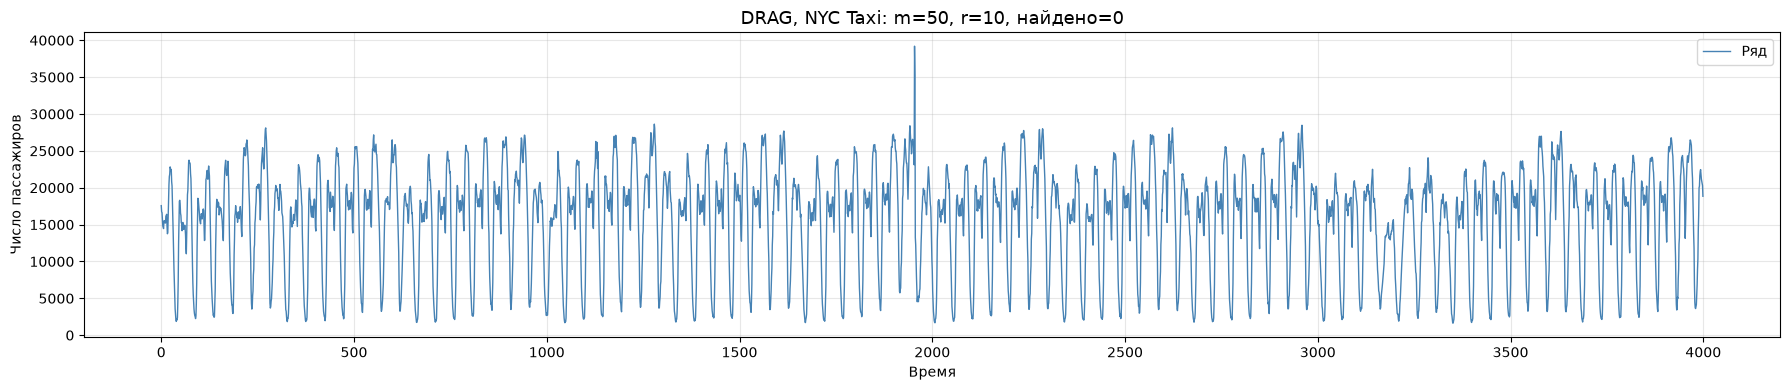

r=5: найдено 0 диссонансов


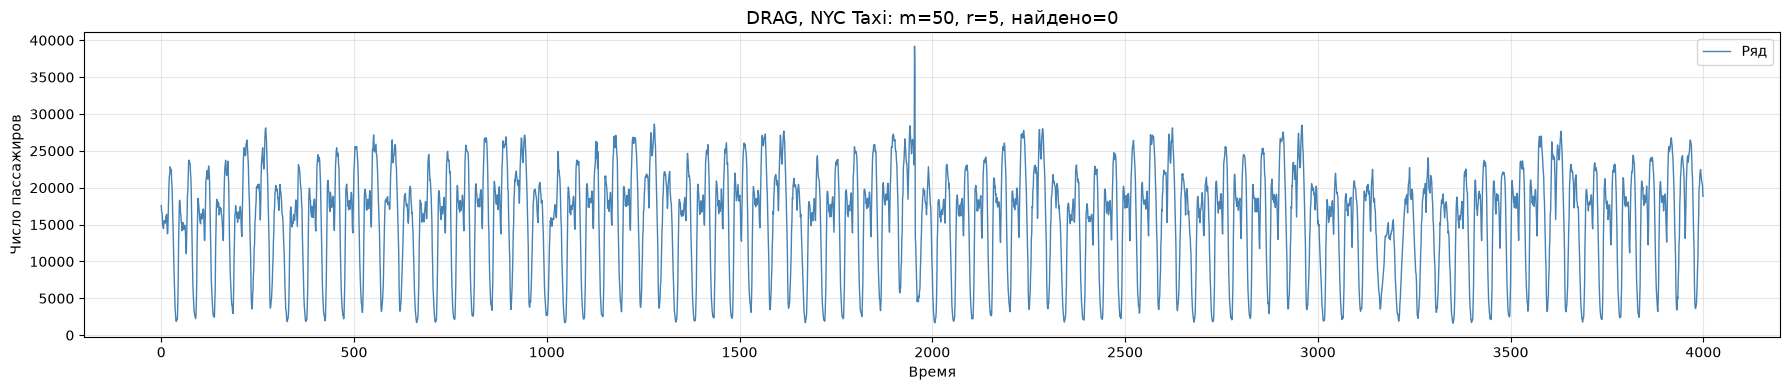

r=3: найдено 4 диссонансов


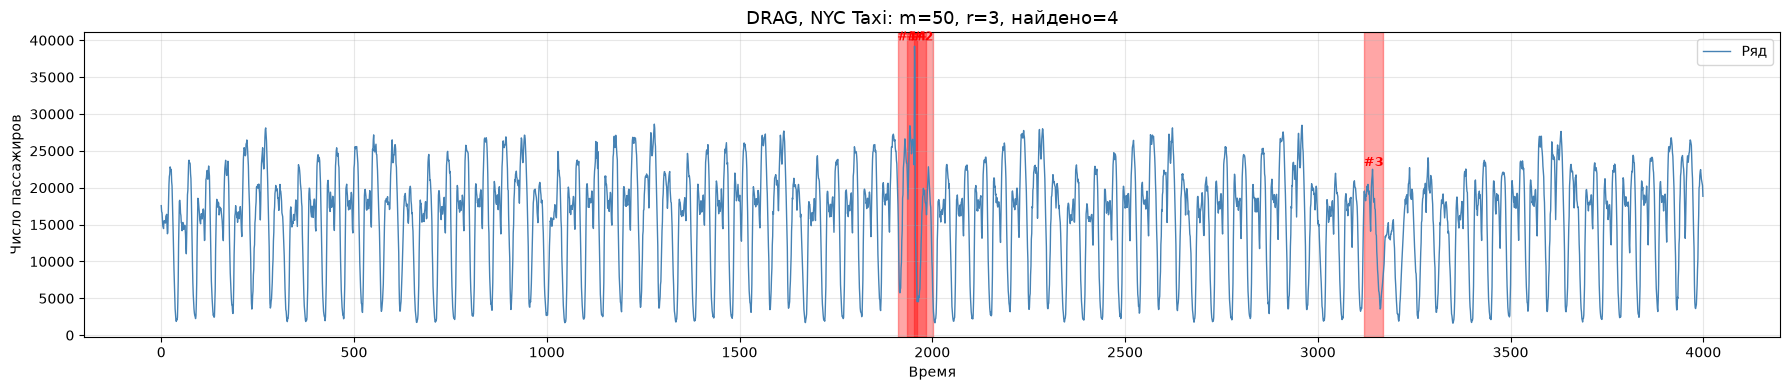

r=1: найдено 42 диссонансов


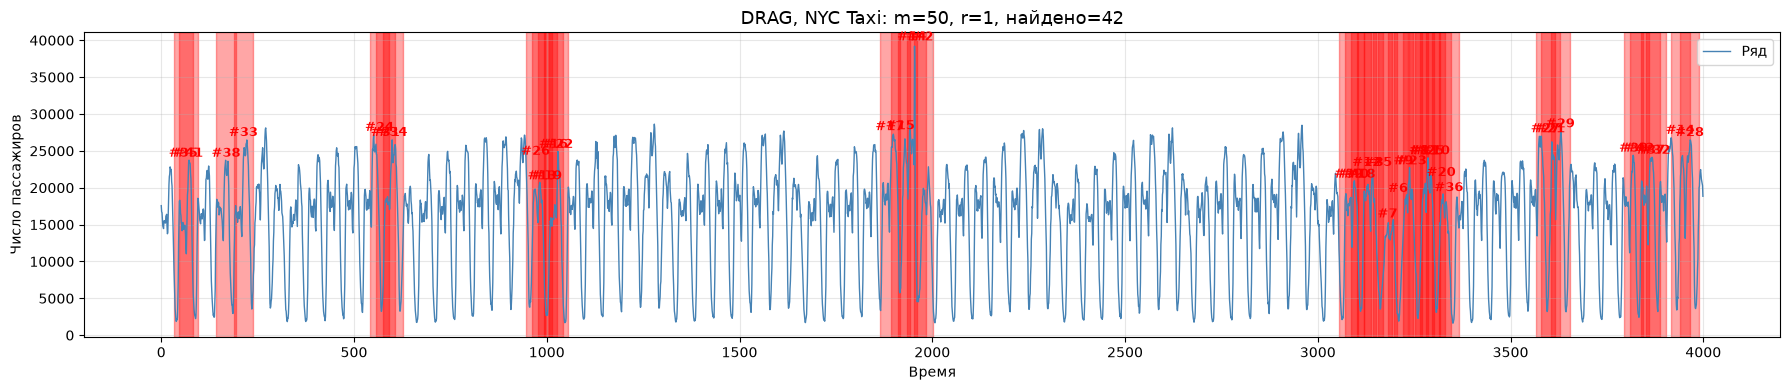

In [21]:
# INSERT YOUR CODE
import matplotlib.pyplot as plt
import numpy as np

# Используем данные такси
data_taxi = nyc_taxi.copy()
m = 50

# Перебираем разные значения r
for r in [10, 5, 3, 1]:
    idxs, _, _ = DRAG(data_taxi, m, r)
    print(f'r={r}: найдено {len(idxs)} диссонансов')

    fig, ax = plt.subplots(figsize=(18, 4))
    ax.plot(data_taxi, color='steelblue', lw=1.0, label='Ряд')

    # Закрашиваем области найденных диссонансов
    for i, idx in enumerate(idxs):
        ax.axvspan(idx, idx + m, color='red', alpha=0.35)
        # Подписываем номер диссонанса
        y_pos = np.max(data_taxi[idx:idx+m]) * 1.02
        ax.text(idx + m/2, y_pos, f'#{i+1}', color='red',
                fontsize=9, ha='center', fontweight='bold')

    ax.set_title(f'DRAG, NYC Taxi: m={m}, r={r}, найдено={len(idxs)}', fontsize=13)
    ax.set_xlabel('Время')
    ax.set_ylabel('Число пассажиров')
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

Чтобы разобраться, почему так происходит и как работает данный алгоритм, ниже мы реализуем все этапы алгоритма DRAG.

Как мы помним из лекций алгоритм DRAG содержит два этапа:

1. Отбор - За одно сканирование ряда сформировать множество кандидатов в диссонансы.
2. Очистка - За одно сканирование ряда отбросить кандидатов, которые являются ложными диссонансами.

##### 3.2.1 Отбор кандидатов

Первым этапом обработки данных является отбор множества потенциальных кандидатов. Мы выбираем из всего множества подпоследовательностей ряда такие, для которых расстояние до правых ближайших соседей больше параметра $r$.

In [22]:
#выбирем более реальное значение для порога
r = 3

In [23]:
T, M_T, Σ_T = core.preprocess(data, m)
#формируем массив длинной равной длине  исходного ряда - m + 1,
#элемент массива является истинным,
#в том случае если подпоследовательность является потенциальным кандидатом
is_cands = find_candidates(T, m, M_T, Σ_T, r, init_cands=None, right=True)
#находим индексы потенциальных кандидатов
cand_index = np.flatnonzero(is_cands)

In [24]:
print(f'{len(cand_index)} {len(cand_index)/len(data)*100} %')

113 11.3 %


Во время отбора кандидатов нам удалось выделить около 113 подпоследовательностей(около 11.3%), которые мы бы могли назвать потенциальными диссонансами.
Это большой процент, который не может нас устраивать как конечный результат.
Если посмотреть на рисунок ниже, мы увидим, что большая часть потенциальных диссонансов расположена в районе смены активности.
К сожалению пресутсвуют и ложные диссонансы, которые случайным образом попали в данный список.

Сформируйте график найденных диссонансов

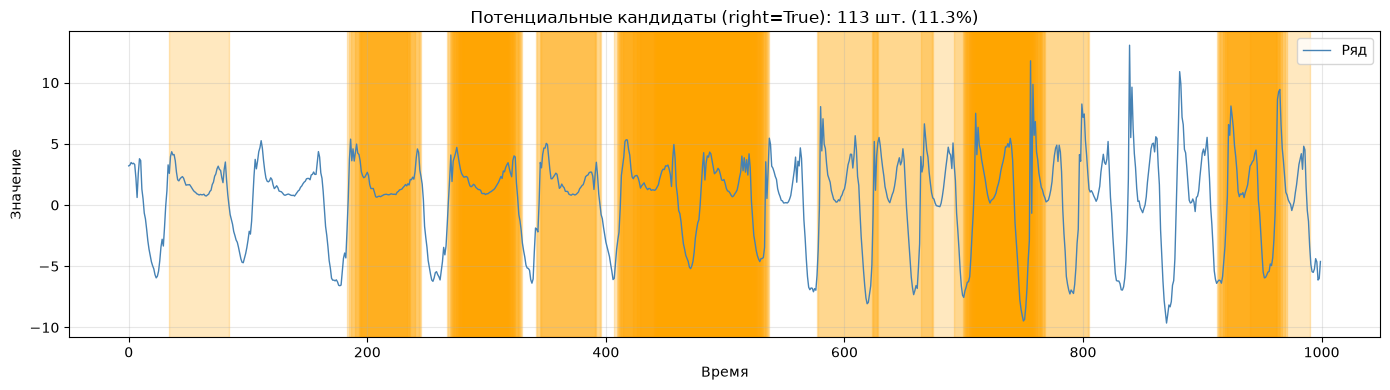

In [25]:
# INSERT YOUR CODE
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(data, color='steelblue', lw=1.0, label='Ряд')

# Закрашиваем области потенциальных кандидатов
for idx in cand_index:
    ax.axvspan(idx, idx + m, color='orange', alpha=0.25)

ax.set_title(f'Потенциальные кандидаты (right=True): {len(cand_index)} шт. ({len(cand_index)/len(data)*100:.1f}%)')
ax.set_xlabel('Время')
ax.set_ylabel('Значение')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

3.2.2 Очистка кандидатов
Как уже упоминалось выше, 11.3% слишком большой процент диссонансов.
Для уменьшения числа потенциальных кандидатов произведем очистку от ложных диссонансов, путем сравнения расстояния до левых ближайших соседей потенциальных диссонансов с порогом $r$.


In [26]:
is_cands = find_candidates(T, m, M_T, Σ_T, r, init_cands=is_cands, right=False)
cands = np.flatnonzero(is_cands)

In [27]:
len(cands)/len(data)*100

2.9000000000000004

Сформируйте график найденных диссонансов

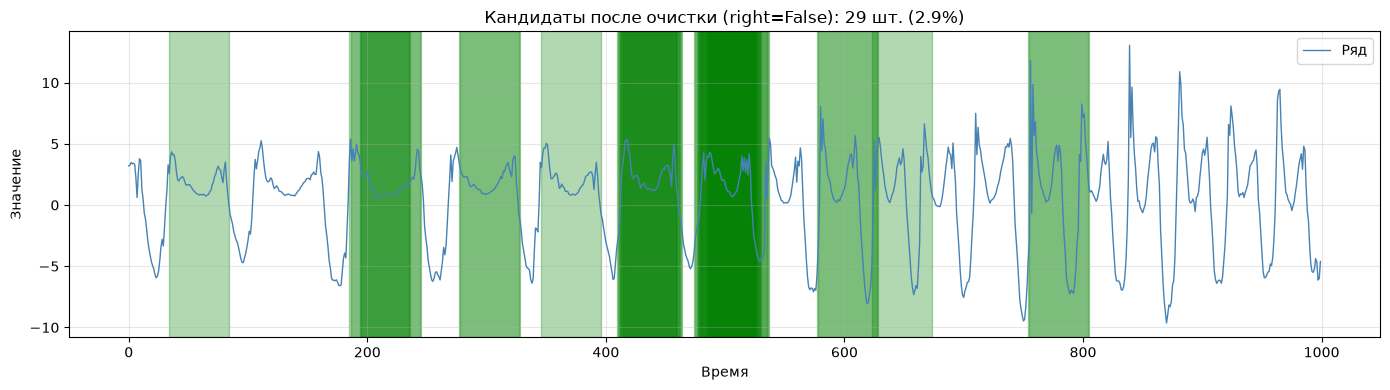

In [28]:
# INSERT YOUR CODE
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(data, color='steelblue', lw=1.0, label='Ряд')

# Закрашиваем области кандидатов, оставшихся после очистки
for idx in cands:
    ax.axvspan(idx, idx + m, color='green', alpha=0.3)

ax.set_title(f'Кандидаты после очистки (right=False): {len(cands)} шт. ({len(cands)/len(data)*100:.1f}%)')
ax.set_xlabel('Время')
ax.set_ylabel('Значение')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Нам удалось сократить число диссонансов до 2.9%. Если проанализировать рисунок, то можно заметить, что большая их часть является тривиальными повторениями подпоследовательности в области смены активности. На следующем шаге избавимся от них.

In [29]:
from modules.drag import refine_candidates
discords_idx, discords_dist, discords_nn_idx = refine_candidates(T, m, M_T, Σ_T, is_cands)
len(discords_idx)/len(data)*100

0.8999999999999999

Сформируйте график найденных диссонансов

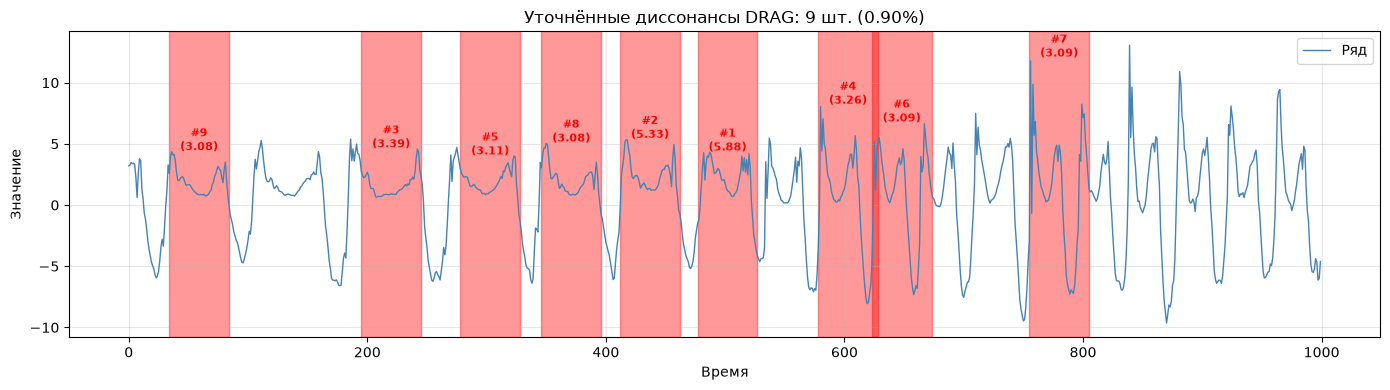

Индексы диссонансов: [np.int64(477), np.int64(412), np.int64(195), np.int64(578), np.int64(278), np.int64(623), np.int64(755), np.int64(346), np.int64(34)]
Расстояния до NN: [np.float64(5.881), np.float64(5.327), np.float64(3.394), np.float64(3.264), np.float64(3.11), np.float64(3.092), np.float64(3.088), np.float64(3.083), np.float64(3.083)]
Индексы ближайших соседей: [np.int64(701), np.int64(346), np.int64(112), np.int64(709), np.int64(115), np.int64(754), np.int64(796), np.int64(34), np.int64(346)]


In [30]:
# INSERT YOUR CODE
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(data, color='steelblue', lw=1.0, label='Ряд')

# Закрашиваем уточнённые диссонансы
for i, idx in enumerate(discords_idx):
    ax.axvspan(idx, idx + m, color='red', alpha=0.4)
    # Подпись с номером и расстоянием до ближайшего соседа
    y_pos = np.max(data[idx:idx+m]) * 1.03
    ax.text(idx + m/2, y_pos, f'#{i+1}\n({discords_dist[i]:.2f})',
            color='red', fontsize=8, ha='center', fontweight='bold')

ax.set_title(f'Уточнённые диссонансы DRAG: {len(discords_idx)} шт. ({len(discords_idx)/len(data)*100:.2f}%)')
ax.set_xlabel('Время')
ax.set_ylabel('Значение')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Выводим индексы и расстояния для справки
print("Индексы диссонансов:", discords_idx)
print("Расстояния до NN:", [round(d, 3) for d in discords_dist])
print("Индексы ближайших соседей:", discords_nn_idx)

##### 3.2.3 Подбор параметров

Реализуйте перебор параметров $m$ и $r$. Подберете параметры таким образом, чтобы алгоритм обнаружил только те диссонансы, которые связаны со сменой активности. Сделайте вывод о том, как эти параметры влияют на качество работы модели.
Подберите оптимальные параметры алгоритма для набора данных такси NY.
Визуализируйте результаты для разных комбинаций. Сделайте выводы.


WALK-RUN: перебор параметров


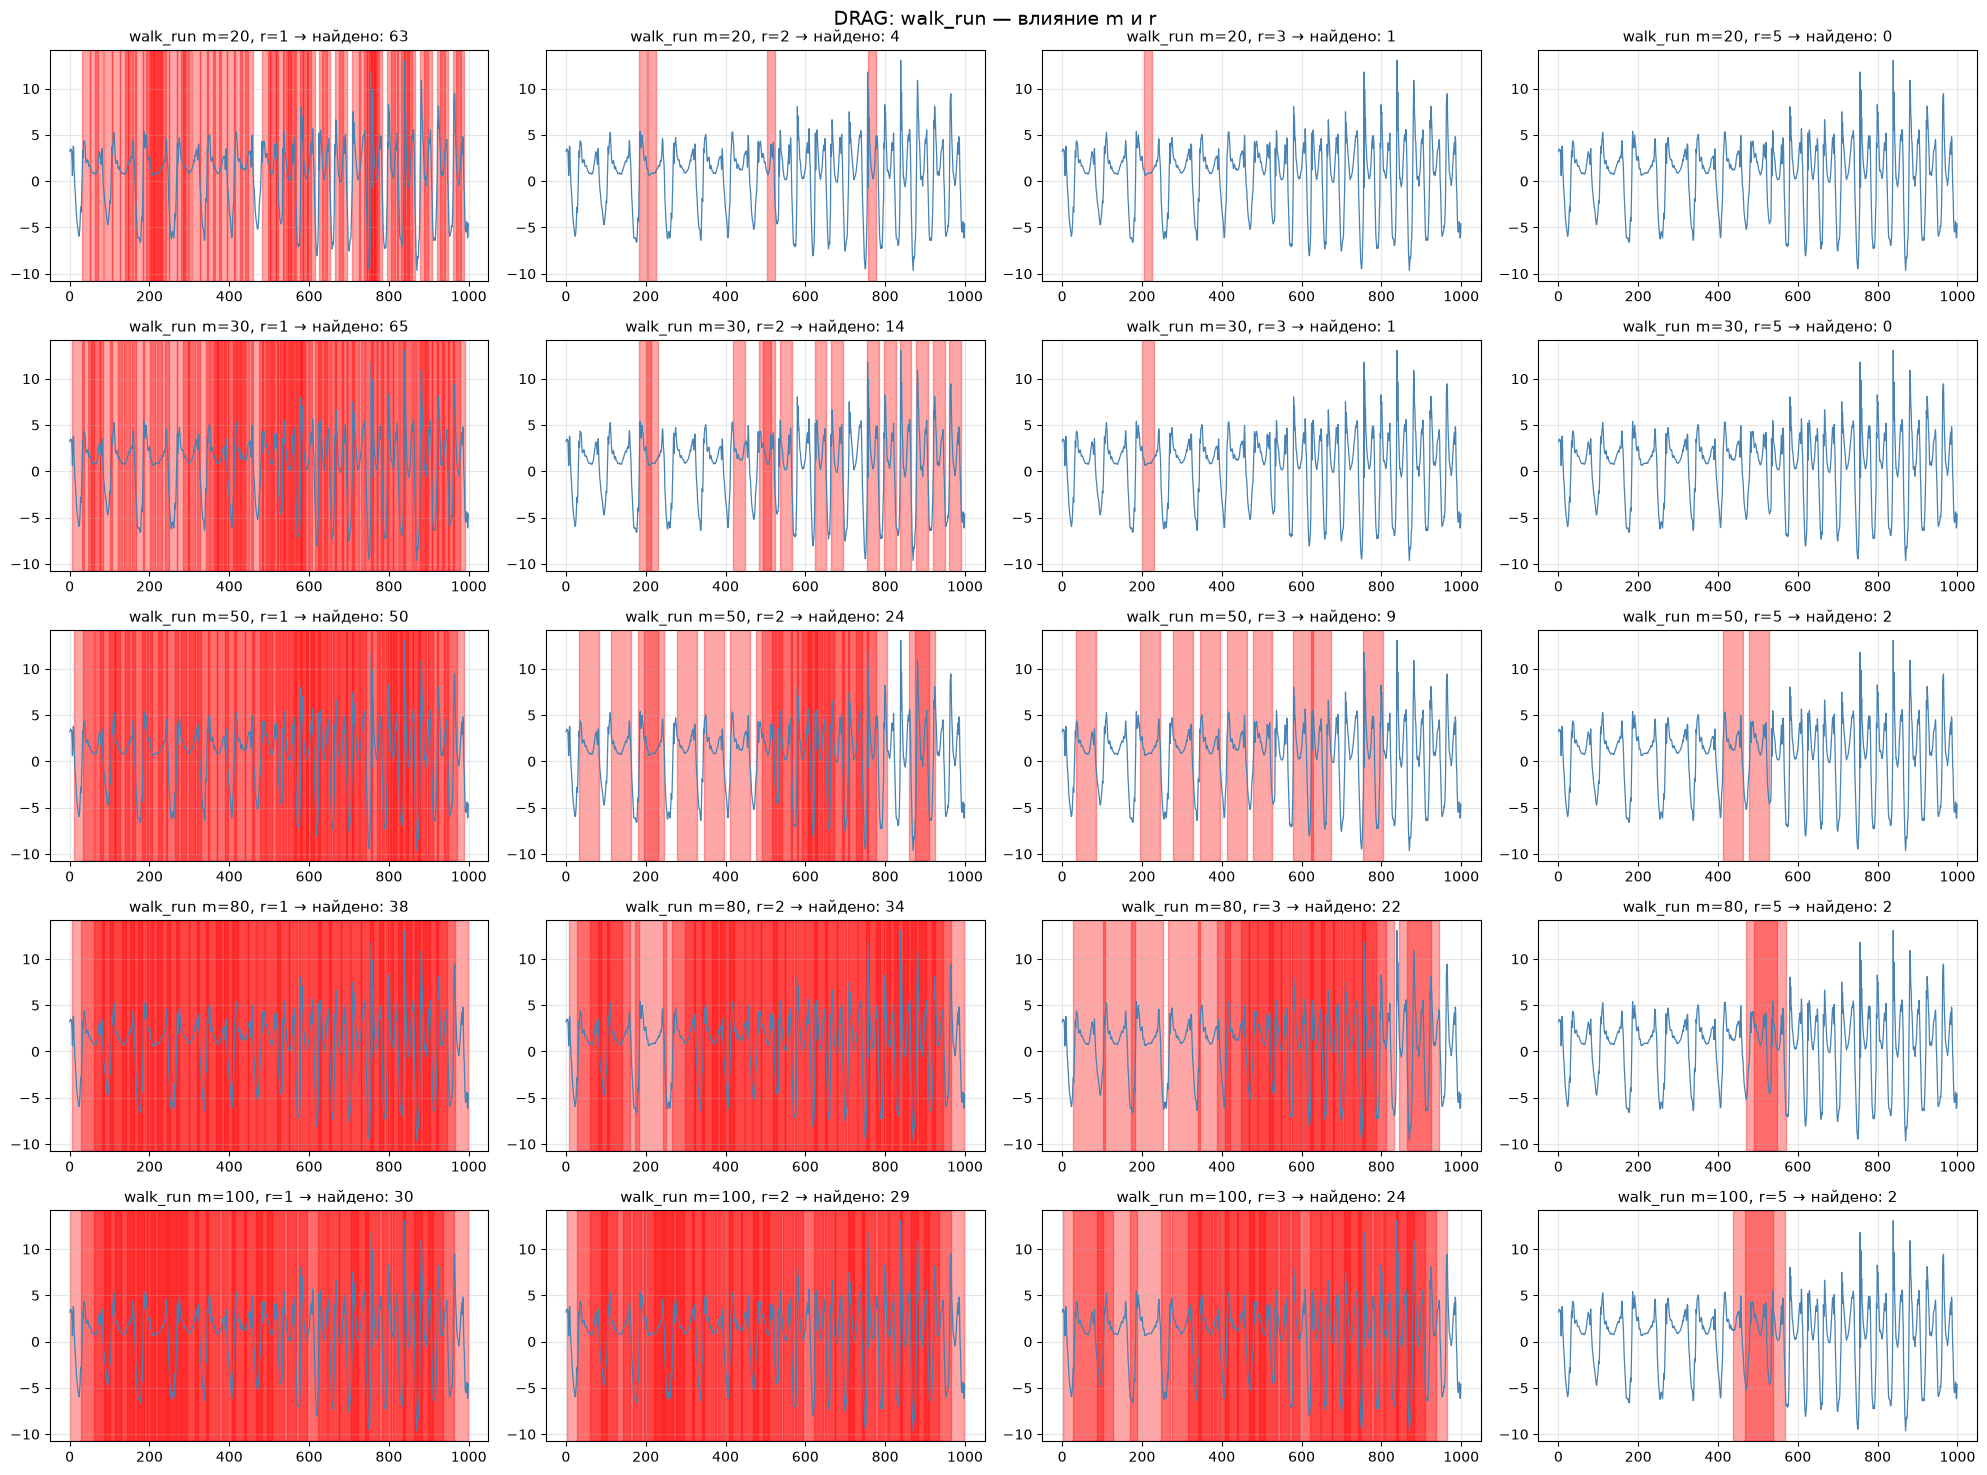

NYC TAXI: перебор параметров


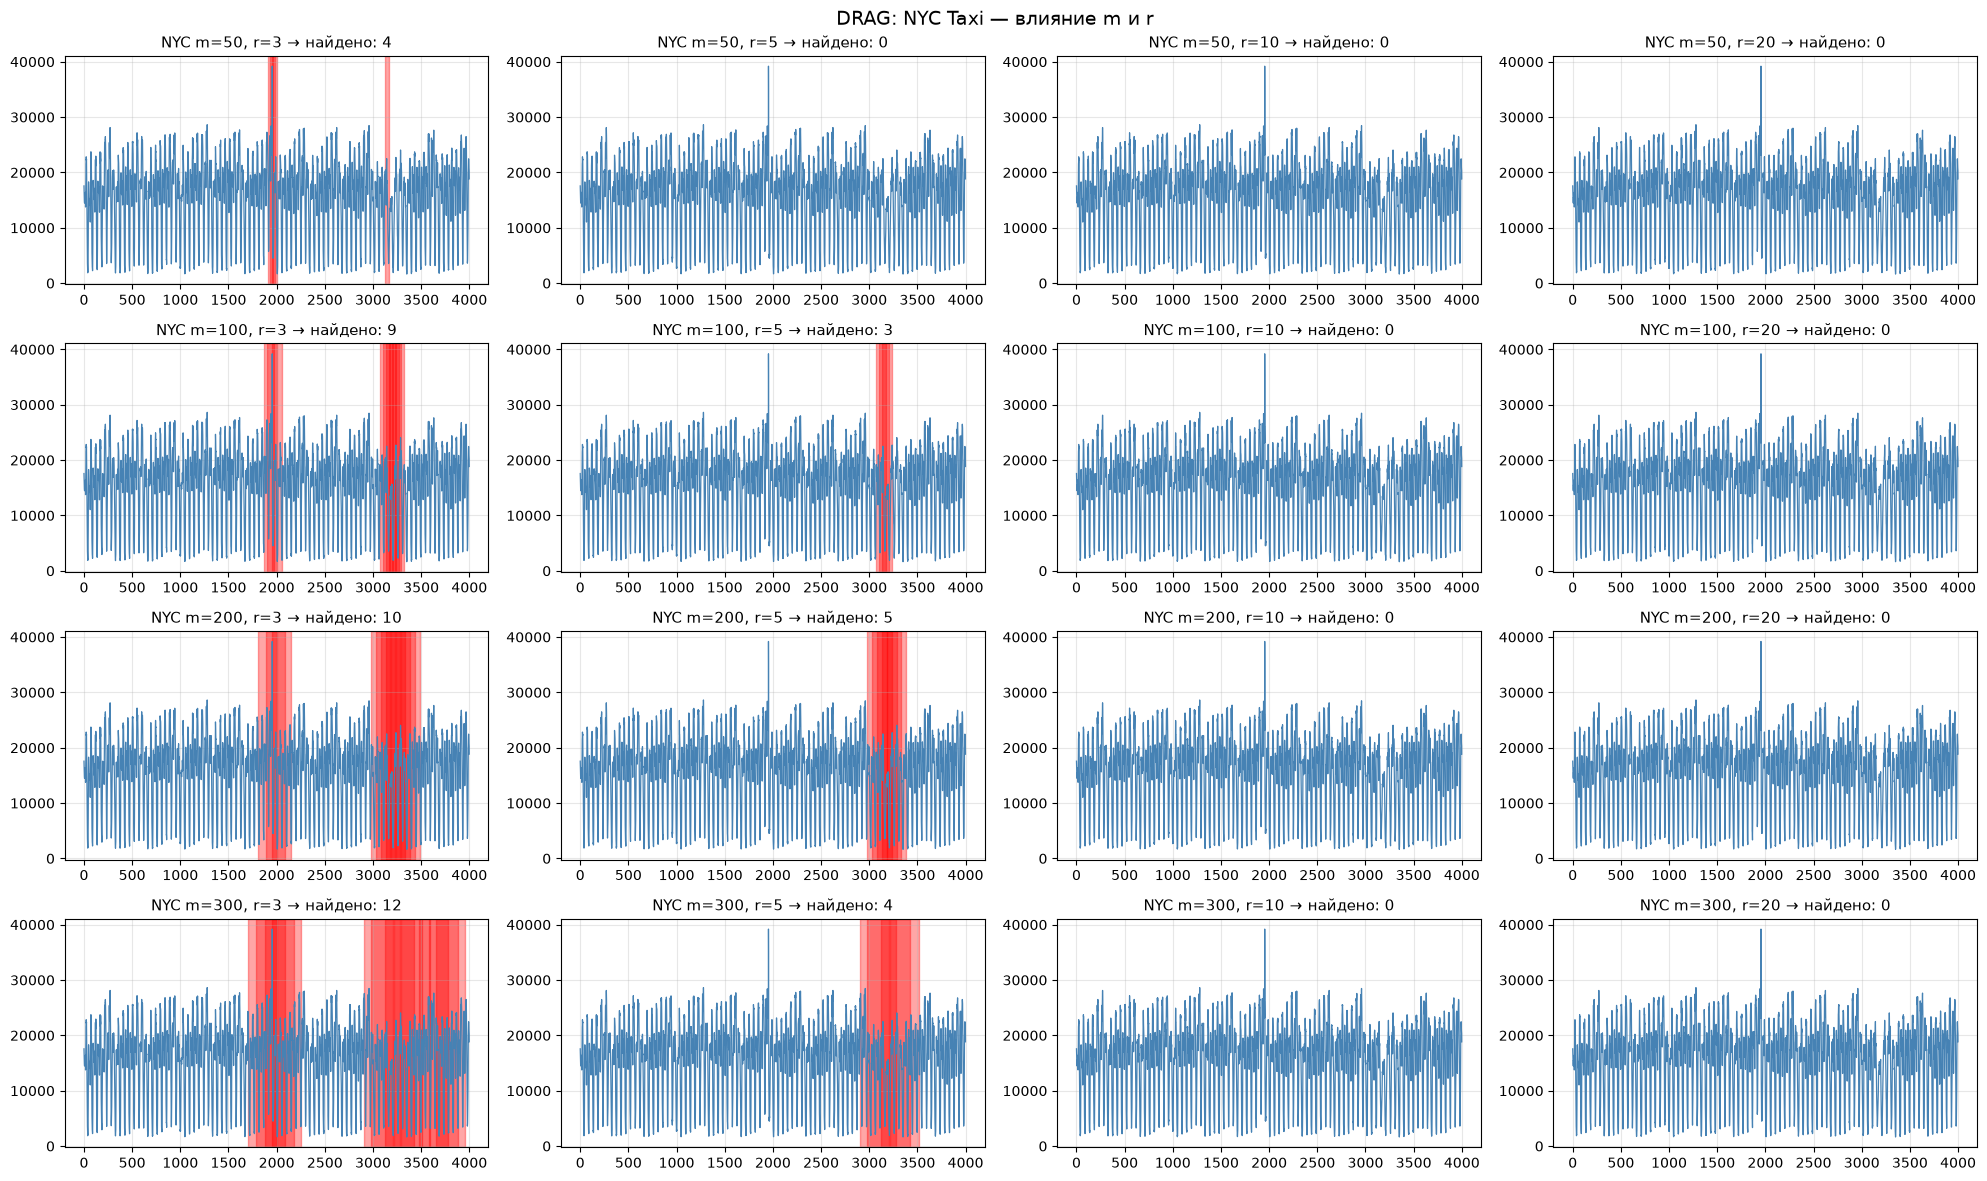


Количество диссонансов — walk_run:
       r=1  r=2  r=3  r=5
m=20    63    4    1    0
m=30    65   14    1    0
m=50    50   24    9    2
m=80    38   34   22    2
m=100   30   29   24    2

Количество диссонансов — NYC Taxi:
       r=3  r=5  r=10  r=20
m=50     4    0     0     0
m=100    9    3     0     0
m=200   10    5     0     0
m=300   12    4     0     0


In [31]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Функция для отрисовки одного результата DRAG
def visualize_drag(ax, data, m, r, title_prefix=''):
    idxs, dists, _ = DRAG(data, m, r)
    ax.plot(data, color='steelblue', lw=0.9)
    for i, idx in enumerate(idxs):
        ax.axvspan(idx, idx + m, color='red', alpha=0.35)
    ax.set_title(f'{title_prefix} m={m}, r={r} → найдено: {len(idxs)}', fontsize=11)
    ax.grid(True, alpha=0.3)
    return len(idxs)


# 1. Walk-run
print("WALK-RUN: перебор параметров")

m_values_walk = [20, 30, 50, 80, 100]
r_values_walk = [1, 2, 3, 5]

fig, axes = plt.subplots(len(m_values_walk), len(r_values_walk),
                         figsize=(20, 3 * len(m_values_walk)))
fig.suptitle('DRAG: walk_run — влияние m и r', fontsize=14)

results_walk = {}
for i, m in enumerate(m_values_walk):
    for j, r in enumerate(r_values_walk):
        n = visualize_drag(axes[i, j], walk_run, m, r, 'walk_run')
        results_walk[(m, r)] = n

plt.tight_layout()
plt.show()


# 2. NYC Taxi
print("NYC TAXI: перебор параметров")

m_values_taxi = [50, 100, 200, 300]
r_values_taxi = [3, 5, 10, 20]

fig, axes = plt.subplots(len(m_values_taxi), len(r_values_taxi),
                         figsize=(20, 3 * len(m_values_taxi)))
fig.suptitle('DRAG: NYC Taxi — влияние m и r', fontsize=14)

results_taxi = {}
for i, m in enumerate(m_values_taxi):
    for j, r in enumerate(r_values_taxi):
        n = visualize_drag(axes[i, j], nyc_taxi, m, r, 'NYC')
        results_taxi[(m, r)] = n

plt.tight_layout()
plt.show()


# 3. Сводные таблицы
print("\nКоличество диссонансов — walk_run:")
df_walk = pd.DataFrame(
    [[results_walk[(m, r)] for r in r_values_walk] for m in m_values_walk],
    index=[f'm={m}' for m in m_values_walk],
    columns=[f'r={r}' for r in r_values_walk]
)
print(df_walk)

print("\nКоличество диссонансов — NYC Taxi:")
df_taxi = pd.DataFrame(
    [[results_taxi[(m, r)] for r in r_values_taxi] for m in m_values_taxi],
    index=[f'm={m}' for m in m_values_taxi],
    columns=[f'r={r}' for r in r_values_taxi]
)
print(df_taxi)

#### **3.3 Поиск диссонансов с помощью алгоритма Merlin**

Как мы уже выяснили подбирать параметры для DRAG простым перебором не очень удобно. Для оптимизации данного процесса в статье [1] был предложен алгоритм Merlin для оптимального поиска подходящего порогового значения.

Условно мы можем разделить поиск диссонансов на три шага:

1. Поиск диссонансов минимальной длинны $minL$. На данном шаге $r = 2\sqrt{minL}$.
2. Поиск диссонансов следующих четырех длин. На данном шаге $r = 0.99 \cdot nndist_{m-1}$. Где $nndist_{m-1}$ - расстояние до ближайшего соседа предыдущего найденного диссонанса.
3. Поиск диссонансов всех
оставшихся дли. $r = \mu - 2 \sigma$. Средние значение и стандартное отклонение вычисляются из расстояний 5 предыдущих диссонансов. н

[1] Nakamura T., Imamura M., Mercer R., Keogh E.J. MERLIN: parameter-free discovery of arbitrary length anomalies in massive time series archives. 20th IEEE Int. Conf. on Data Mining, ICDM 2020, Sorrento, Italy, November 17-20, 2020. pp. 1190-1195. IEEE (2020). https://doi.org/10.1109/ICDM50108.2020.00147

##### 3.3.1 Поиск диссонансов минимальной длинны

Вспомнил последовательность действий первого шага алгоритма:
![merlin-part-first](pics/first_part.png)

В данной работе мы внесем небольшое изменение, мы будем считать, что подпоследовательность может быть диссонансом только в том случае, если больше 75% точек, не входят в состав других диссонансов.

In [32]:
T = walk_run
m = 50
# сформируем массив метод для потенциальных кандидатов в диссонансы.
# после каждого найденного диссонанса,
# мы будем исключать окружающие его подпоследовательности из числа потенциальных кандидатов,
# путем замены значений их меток на false
excl_zone = int(np.ceil(m / 4))
include = np.ones(len(T)-m+1, dtype=bool)
# Количество диссонансов, которые мы будем искать
topK = 10


In [33]:
dis_idx = -np.ones((topK))
dis_nnDist = -np.ones((topK))
dis_nn_idx = np.full((topK),-np.inf)
#первое прближение r
r = 2*np.sqrt(m)
minL = m
maxL = int(m+np.ceil(m*0.1))
#количество найденных диссонасов
cound_find_dis = 0

while dis_nnDist[cound_find_dis-1]<0 and cound_find_dis<topK:
    result = DRAG(data=T,m=minL,r=r, include =include)
    for diss, nnDist, nn in zip(*result):
        dis_idx[cound_find_dis] = diss
        dis_nnDist[cound_find_dis] = nnDist
        dis_nn_idx[cound_find_dis] = nn
        #исключаем окружающие найденный диссонас
        #подпоследовательности и числа потенциальных диссонасов
        core.apply_exclusion_zone(include, diss, excl_zone, False)
        cound_find_dis+=1
        if cound_find_dis>=topK:
            break
    r*=0.5

In [34]:
maxL

55

In [35]:
print('Количество найденных на первом этапе диссонансов:', cound_find_dis)

Количество найденных на первом этапе диссонансов: 2


На первом шаге нам удалось выделить 2 диссонанса из 10 требуемых.
Реализуйте, оставшиеся шаги алгоритма, чтобы найти оставшиеся диссонансы.

![merlin-part-first](pics/second_part.png)


Walk-run: найдено 9 диссонансов


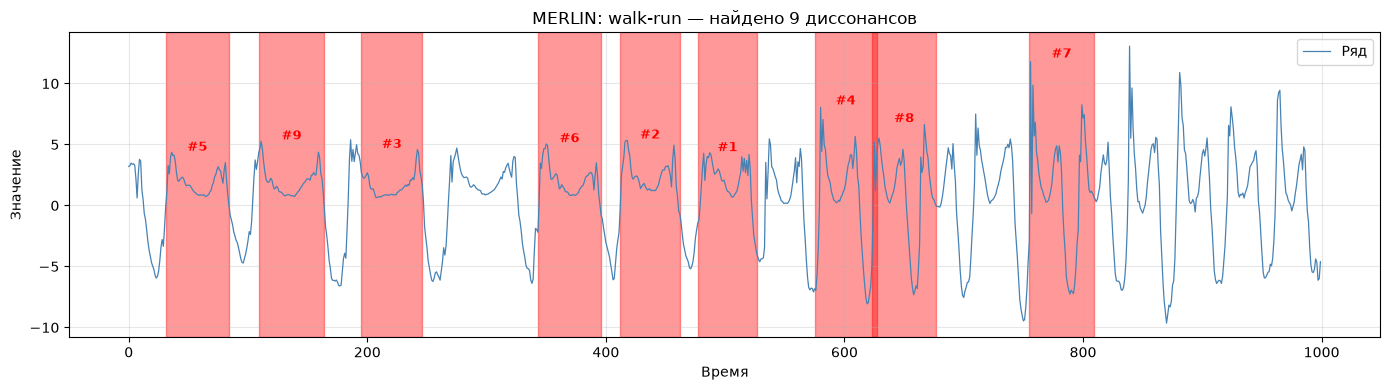

In [36]:
# INSERT YOUR CODE
import numpy as np
import matplotlib.pyplot as plt
from stumpy import core
from modules.drag import DRAG

def merlin_discords(T, minL, topK=10, maxL=None):
    """
    Полная реализация алгоритма Merlin (Nakamura et al., 2020).
    Шаги:
      1) r = 2*sqrt(minL) для длины minL.
      2) r = 0.99 * nnDist_{i-1} для длин minL+1 ... minL+4.
      3) r = mu - 2*sigma по 5 предыдущим nnDist для длин minL+5 ... maxL.
    Возвращает: (idx, len, nnDist, nn_idx).
    """
    T = np.asarray(T).astype(np.float64)
    if maxL is None:
        maxL = int(minL + np.ceil(minL * 0.1))

    excl_zone = int(np.ceil(minL / 4))
    include = np.ones(len(T) - minL + 1, dtype=bool)

    dis_idx = -np.ones(topK, dtype=int)
    dis_len = -np.ones(topK, dtype=int)
    dis_nnDist = -np.ones(topK)
    dis_nn_idx = np.full(topK, -np.inf)
    n_found = 0

    def _add(result):
        nonlocal n_found
        for diss, nnDist, nn in zip(*result):
            if n_found >= topK:
                return
            dis_idx[n_found] = diss
            dis_len[n_found] = L
            dis_nnDist[n_found] = nnDist
            dis_nn_idx[n_found] = nn
            core.apply_exclusion_zone(include, diss, excl_zone, False)
            n_found += 1

    # Шаг 1: minL, r = 2*sqrt(minL)
    L = minL
    r = 2 * np.sqrt(minL)
    while n_found < topK and r > 1e-6:
        result = DRAG(data=T, m=L, r=r, include=include)
        if len(result[0]) > 0:
            _add(result)
            break
        r *= 0.5

    # Шаг 2: длины minL+1 ... minL+4, r = 0.99*nnDist_{i-1}
    for L in range(minL + 1, minL + 5):
        if n_found >= topK:
            break
        r = 0.99 * dis_nnDist[n_found - 1] if n_found > 0 else 2 * np.sqrt(L)
        while n_found < topK and r > 1e-6:
            result = DRAG(data=T, m=L, r=r, include=include)
            if len(result[0]) > 0:
                _add(result)
                break
            r *= 0.99

    # Шаг 3: длины minL+5 ... maxL, r = mu - 2*sigma
    for L in range(minL + 5, maxL + 1):
        if n_found >= topK:
            break
        prev = dis_nnDist[max(0, n_found - 5):n_found]
        prev = prev[prev >= 0]
        if len(prev) >= 2:
            mu, sigma = np.mean(prev), np.std(prev)
            r = mu - 2 * sigma
        elif n_found > 0:
            r, sigma = 0.99 * dis_nnDist[n_found - 1], 0.0
        else:
            r, sigma = 2 * np.sqrt(L), 0.0
        if r <= 0:
            r = 0.1
        while n_found < topK and r > 1e-6:
            result = DRAG(data=T, m=L, r=r, include=include)
            if len(result[0]) > 0:
                _add(result)
                break
            r -= sigma if sigma > 0 else r * 0.5

    return (dis_idx[:n_found], dis_len[:n_found],
            dis_nnDist[:n_found], dis_nn_idx[:n_found])


# Применяем к walk_run
disc_idx_w, disc_len_w, disc_nn_w, disc_nn_idx_w = merlin_discords(
    walk_run, minL=50, topK=10
)
print(f'Walk-run: найдено {len(disc_idx_w)} диссонансов')

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(walk_run, color='steelblue', lw=0.9, label='Ряд')
for i, (idx, L) in enumerate(zip(disc_idx_w, disc_len_w)):
    idx = int(idx); L = int(L)
    ax.axvspan(idx, idx + L, color='red', alpha=0.4)
    ax.text(idx + L / 2, np.max(walk_run[idx:idx + L]) * 1.03,
            f'#{i+1}', color='red', ha='center', fontsize=9, fontweight='bold')
ax.set_title(f'MERLIN: walk-run — найдено {len(disc_idx_w)} диссонансов')
ax.set_xlabel('Время'); ax.set_ylabel('Значение')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

Найдите диссонансы набора такси NY. Визуализируйте найденные диссонансы для обоих наборов данных, сравните с результатами остальных методов.


NYC Taxi: найдено 10 диссонансов


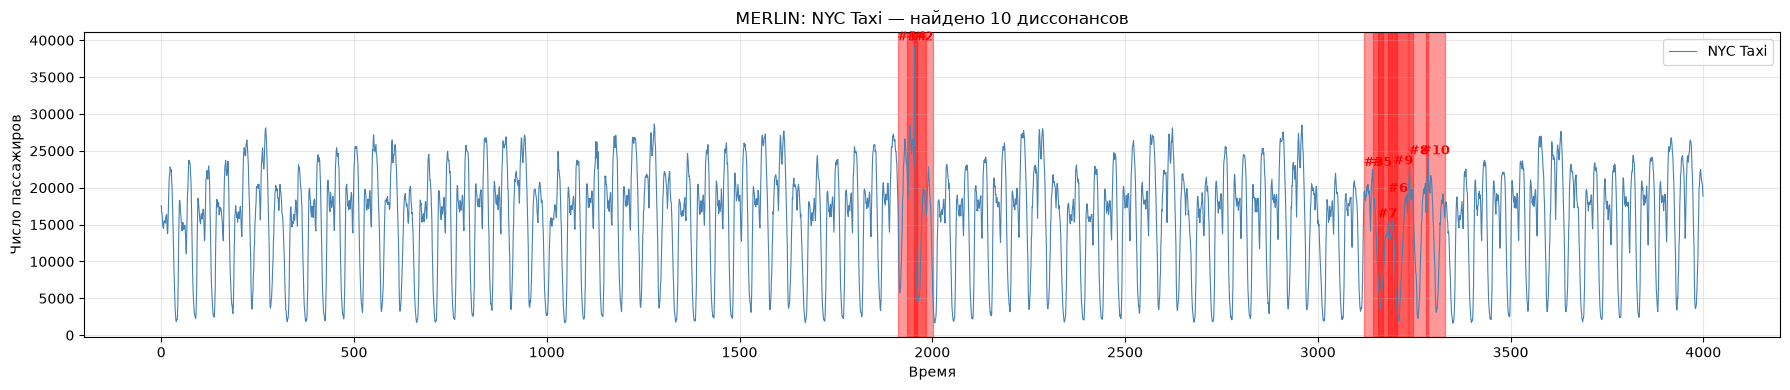

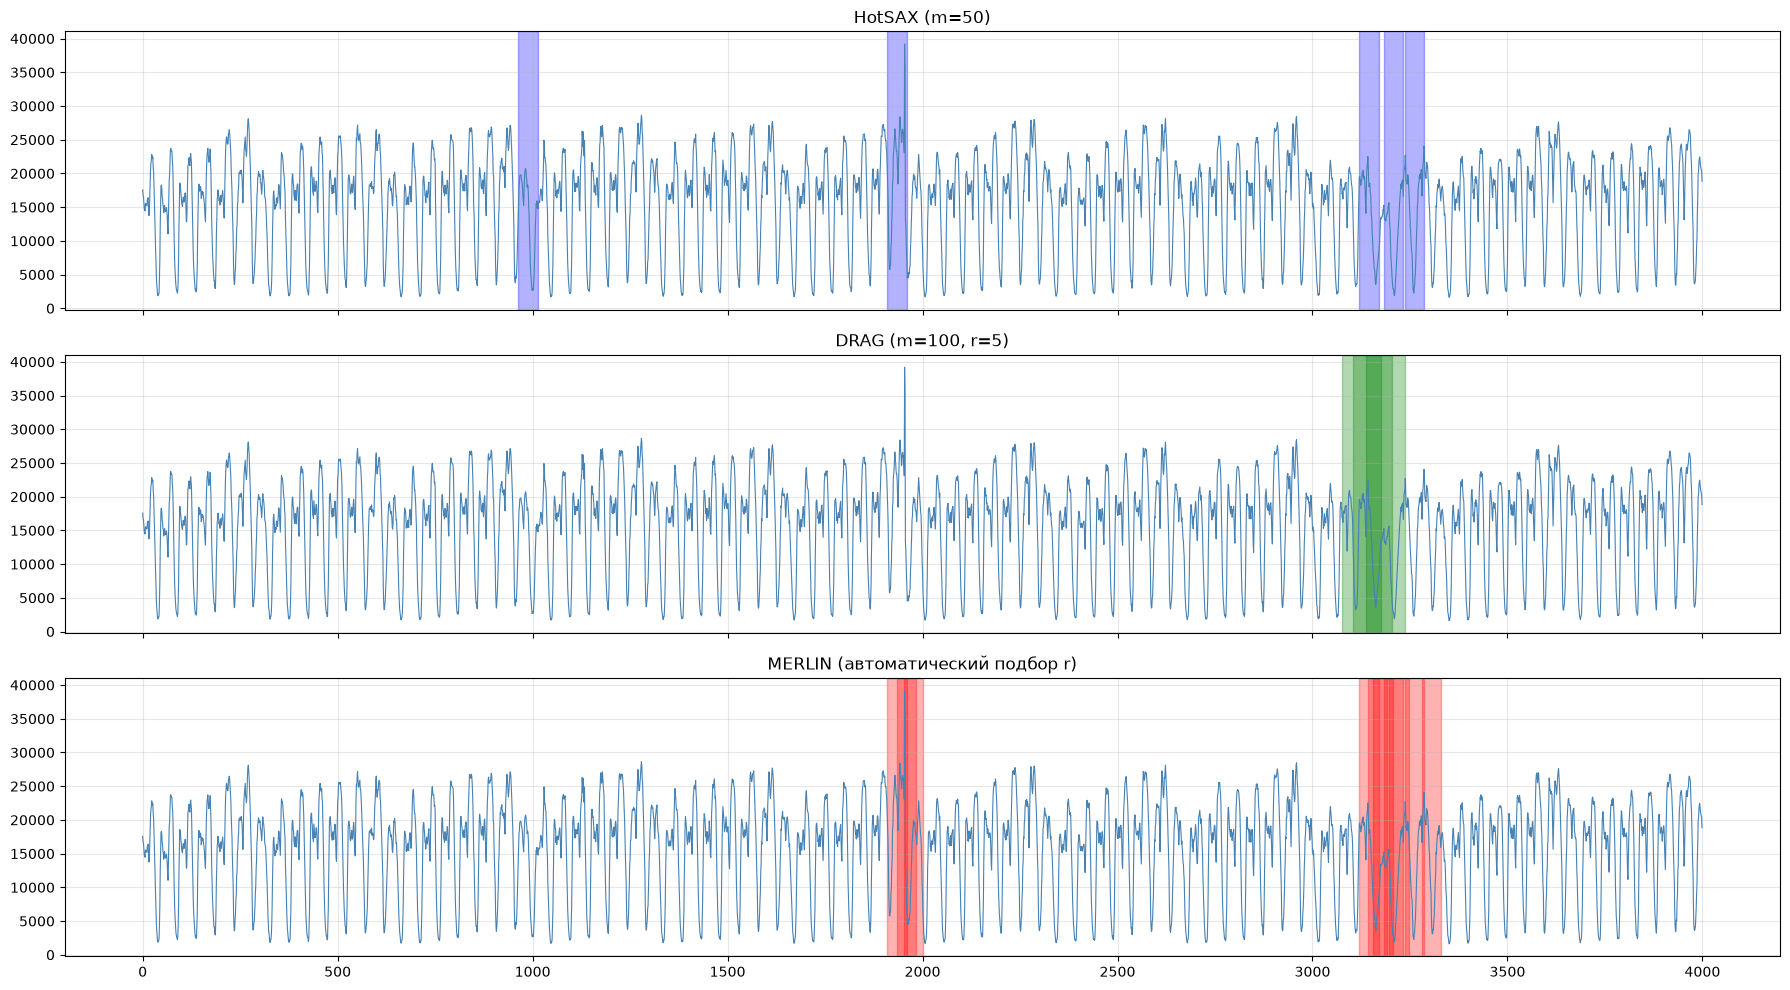

In [37]:
# INSERT YOUR CODE
# Применяем Merlin к NYC Taxi
disc_idx_t, disc_len_t, disc_nn_t, _ = merlin_discords(
    nyc_taxi, minL=50, topK=10
)
print(f'NYC Taxi: найдено {len(disc_idx_t)} диссонансов')

fig, ax = plt.subplots(figsize=(18, 4))
ax.plot(nyc_taxi, color='steelblue', lw=0.8, label='NYC Taxi')
for i, (idx, L) in enumerate(zip(disc_idx_t, disc_len_t)):
    idx = int(idx); L = int(L)
    ax.axvspan(idx, idx + L, color='red', alpha=0.4)
    ax.text(idx + L / 2, np.max(nyc_taxi[idx:idx + L]) * 1.02,
            f'#{i+1}', color='red', ha='center', fontsize=9, fontweight='bold')
ax.set_title(f'MERLIN: NYC Taxi — найдено {len(disc_idx_t)} диссонансов')
ax.set_xlabel('Время'); ax.set_ylabel('Число пассажиров')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# Сравнение с HotSAX и DRAG
fig, axes = plt.subplots(3, 1, figsize=(18, 10), sharex=True)

# 1) HotSAX
axes[0].plot(nyc_taxi, color='steelblue', lw=0.8)
for d in discords_taxi_hotsax:
    idx = int(d[0])
    axes[0].axvspan(idx, idx + 50, color='blue', alpha=0.3)
axes[0].set_title('HotSAX (m=50)')
axes[0].grid(True, alpha=0.3)

# 2) DRAG (с параметрами, подобранными ранее)
idxs_drag_taxi, _, _ = DRAG(nyc_taxi, m=100, r=5)
axes[1].plot(nyc_taxi, color='steelblue', lw=0.8)
for idx in idxs_drag_taxi:
    axes[1].axvspan(idx, idx + 100, color='green', alpha=0.3)
axes[1].set_title('DRAG (m=100, r=5)')
axes[1].grid(True, alpha=0.3)

# 3) Merlin
axes[2].plot(nyc_taxi, color='steelblue', lw=0.8)
for idx, L in zip(disc_idx_t, disc_len_t):
    axes[2].axvspan(int(idx), int(idx) + int(L), color='red', alpha=0.3)
axes[2].set_title('MERLIN (автоматический подбор r)')
axes[2].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()